# Adaptive Client Weighting in Federated Learning
improve project by allowing the global model to assign different weights to different clients instead of relying only on the number of training samples.

 objective:
1. Load the existing federated-learning models.
2. Calculate standard FedAvg weights.
3. Calculate adaptive weights using client data size and model-update magnitude.
4. Build an adaptively aggregated global model.
5. Compare standard FedAvg and adaptive FedAvg on the same test edges.
6. Save metrics, weights, and graphs.
The adaptive weighting method will be a prototype heuristic—not a guarantee that the model will always perform better.

In [1]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch_geometric.nn import GCNConv
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

BASE = Path("D:/adaptive_federated_gnn")
OUT = BASE / "outputs/day19"
OUT.mkdir(parents=True, exist_ok=True)

GRAPH_PATH = BASE / "data/processed/edge_graph.pt"
DAY10_PATH = BASE / "outputs/day10/federated_clients.pt"
DAY16_PATH = BASE / "outputs/day16/non_iid_clients.pt"
DAY17 = BASE / "outputs/day17"

# Load graph
graph = torch.load(
    GRAPH_PATH, map_location="cpu", weights_only=False
)

edge_index = graph["edge_index"].long()
edge_features = graph["edge_attr"].float()
edge_labels = graph["edge_label"].long().view(-1)

num_nodes = int(edge_index.max().item()) + 1
num_edge_features = edge_features.shape[1]

# Load client data and model states
day10_clients = torch.load(
    DAY10_PATH, map_location="cpu", weights_only=False
)

client_data = torch.load(
    DAY16_PATH, map_location="cpu", weights_only=False
)

shared_state = torch.load(
    DAY17 / "shared_initial_model.pt",
    map_location="cpu", weights_only=False
)

client_states = {
    name: torch.load(
        DAY17 / f"{name}_retrained_model.pt",
        map_location="cpu",
        weights_only=False
    )
    for name in ["client_1", "client_2", "client_3"]
}

client_names = list(client_states.keys())

print("Graph edges:", edge_index.shape[1])
print("Edge features:", num_edge_features)
print("Clients:", client_names)
print("Output folder:", OUT)

c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Graph edges: 286095
Edge features: 67
Clients: ['client_1', 'client_2', 'client_3']
Output folder: D:\adaptive_federated_gnn\outputs\day19


In [2]:
class EdgeGCN(nn.Module):
    def __init__(
        self,
        num_nodes,
        edge_feature_size,
        embedding_size=16,
        hidden_size=32
    ):
        super().__init__()

        self.node_embeddings = nn.Embedding(
            num_nodes, embedding_size
        )
        self.conv1 = GCNConv(embedding_size, hidden_size)
        self.conv2 = GCNConv(hidden_size, hidden_size)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2 + edge_feature_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, edge_index, edge_features):
        node_ids = torch.arange(
            self.node_embeddings.num_embeddings,
            device=edge_index.device
        )

        x = self.node_embeddings(node_ids)
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))

        source_embeddings = x[edge_index[0]]
        destination_embeddings = x[edge_index[1]]

        combined = torch.cat(
            [source_embeddings, destination_embeddings, edge_features],
            dim=1
        )

        return self.classifier(combined)


print("EdgeGCN architecture defined successfully.")

EdgeGCN architecture defined successfully.


# Calculate standard and adaptive client weights
- Standard FedAvg: weights clients according to their number of training edges.
- Adaptive FedAvg: starts with sample-size weights, then reduces the relative influence of clients whose model updates differ more strongly in magnitude from the median update magnitude.

In [3]:
# Calculate each client's training sample count
client_sizes = {
    name: len(client_data[name]["edge_labels"])
    for name in client_names
}

total_samples = sum(client_sizes.values())

standard_weights = {
    name: client_sizes[name] / total_samples
    for name in client_names
}

# Measure each client's update magnitude from the shared initial model
update_norms = {}

for name in client_names:
    squared_norm = 0.0

    for key, base_tensor in shared_state.items():
        base = base_tensor.float()
        local = client_states[name][key].float()
        delta = local - base

        squared_norm += torch.sum(delta ** 2).item()

    update_norms[name] = squared_norm ** 0.5

# Prevent division by zero
median_norm = max(float(np.median(list(update_norms.values()))), 1e-12)

# Larger-than-median update magnitudes receive a lower reliability factor
reliability = {
    name: 1.0 / (1.0 + update_norms[name] / median_norm)
    for name in client_names
}

unnormalized = {
    name: standard_weights[name] * reliability[name]
    for name in client_names
}

weight_total = sum(unnormalized.values())

adaptive_weights = {
    name: unnormalized[name] / weight_total
    for name in client_names
}

weights_df = pd.DataFrame({
    "client": client_names,
    "training_edges": [client_sizes[n] for n in client_names],
    "standard_weight": [standard_weights[n] for n in client_names],
    "update_norm": [update_norms[n] for n in client_names],
    "reliability_factor": [reliability[n] for n in client_names],
    "adaptive_weight": [adaptive_weights[n] for n in client_names]
})

weights_df.to_csv(OUT / "adaptive_client_weights.csv", index=False)
display(weights_df)

print("Standard weights sum:", sum(standard_weights.values()))
print("Adaptive weights sum:", sum(adaptive_weights.values()))

,client,training_edges,standard_weight,update_norm,reliability_factor,adaptive_weight
0,client_1,66756,0.333337,0.400369,0.500000,0.326987
1,client_2,66755,0.333332,0.305792,0.566965,0.370775
2,client_3,66755,0.333332,0.465926,0.462163,0.302238


Standard weights sum: 1.0
Adaptive weights sum: 0.9999999999999999


In [4]:
def aggregate_client_models(weights):
    aggregated_state = {}

    for key, base_tensor in shared_state.items():
        base = base_tensor.float()
        combined_delta = torch.zeros_like(base)

        for name in client_names:
            local = client_states[name][key].float()
            combined_delta += weights[name] * (local - base)

        aggregated_state[key] = (base + combined_delta).to(
            dtype=base_tensor.dtype
        )

    return aggregated_state


standard_state = aggregate_client_models(standard_weights)
adaptive_state = aggregate_client_models(adaptive_weights)

standard_model_path = OUT / "standard_fedavg_model.pt"
adaptive_model_path = OUT / "adaptive_fedavg_model.pt"

torch.save(standard_state, standard_model_path)
torch.save(adaptive_state, adaptive_model_path)

print("Standard model saved:", standard_model_path)
print("Adaptive model saved:", adaptive_model_path)

Standard model saved: D:\adaptive_federated_gnn\outputs\day19\standard_fedavg_model.pt
Adaptive model saved: D:\adaptive_federated_gnn\outputs\day19\adaptive_fedavg_model.pt


In [5]:
train_indices = np.unique(np.concatenate([
    (
        data["local_edge_indices"].cpu().numpy()
        if torch.is_tensor(data["local_edge_indices"])
        else np.asarray(data["local_edge_indices"])
    )
    for data in day10_clients.values()
])).astype(np.int64)

train_indices = train_indices[
    (train_indices >= 0) & (train_indices < len(edge_labels))
]

train_mask = np.zeros(len(edge_labels), dtype=bool)
train_mask[train_indices] = True

test_indices = np.flatnonzero(~train_mask)

if len(test_indices) == 0:
    raise ValueError("No held-out test edges found. Check the Day 10 split.")

test_indices_t = torch.tensor(test_indices, dtype=torch.long)
y_test = edge_labels[test_indices_t].numpy()

print("Training edges:", int(train_mask.sum()))
print("Test edges:", len(test_indices))
print("Test benign edges:", int((y_test == 0).sum()))
print("Test attack edges:", int((y_test == 1).sum()))

Training edges: 200266
Test edges: 85829
Test benign edges: 38188
Test attack edges: 47641


In [6]:
def evaluate_model_state(state, model_name):
    model = EdgeGCN(
        num_nodes=num_nodes,
        edge_feature_size=num_edge_features
    )

    model.load_state_dict(state)
    model.eval()

    with torch.no_grad():
        logits = model(edge_index, edge_features)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        predictions = logits.argmax(dim=1)

    y_pred = predictions[test_indices_t].numpy()
    y_prob = probabilities[test_indices_t].numpy()

    results = {
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }

    if len(np.unique(y_test)) == 2:
        results["roc_auc"] = roc_auc_score(y_test, y_prob)
        results["pr_auc"] = average_precision_score(y_test, y_prob)
    else:
        results["roc_auc"] = np.nan
        results["pr_auc"] = np.nan

    predictions_df = pd.DataFrame({
        "edge_index": test_indices,
        "actual_label": y_test,
        "predicted_label": y_pred,
        "attack_probability": y_prob
    })

    predictions_df.to_csv(
        OUT / f"{model_name.lower()}_predictions.csv",
        index=False
    )

    return results, y_pred


standard_results, standard_predictions = evaluate_model_state(
    standard_state, "Standard_FedAvg"
)

adaptive_results, adaptive_predictions = evaluate_model_state(
    adaptive_state, "Adaptive_FedAvg"
)

comparison_df = pd.DataFrame([
    standard_results,
    adaptive_results
])

comparison_df.to_csv(
    OUT / "model_comparison_metrics.csv",
    index=False
)

display(comparison_df)

,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Standard_FedAvg,0.413275,0.007968,0.000462,0.000873,0.876633,0.789229
1,Adaptive_FedAvg,0.412786,0.007849,0.000462,0.000872,0.876200,0.788830


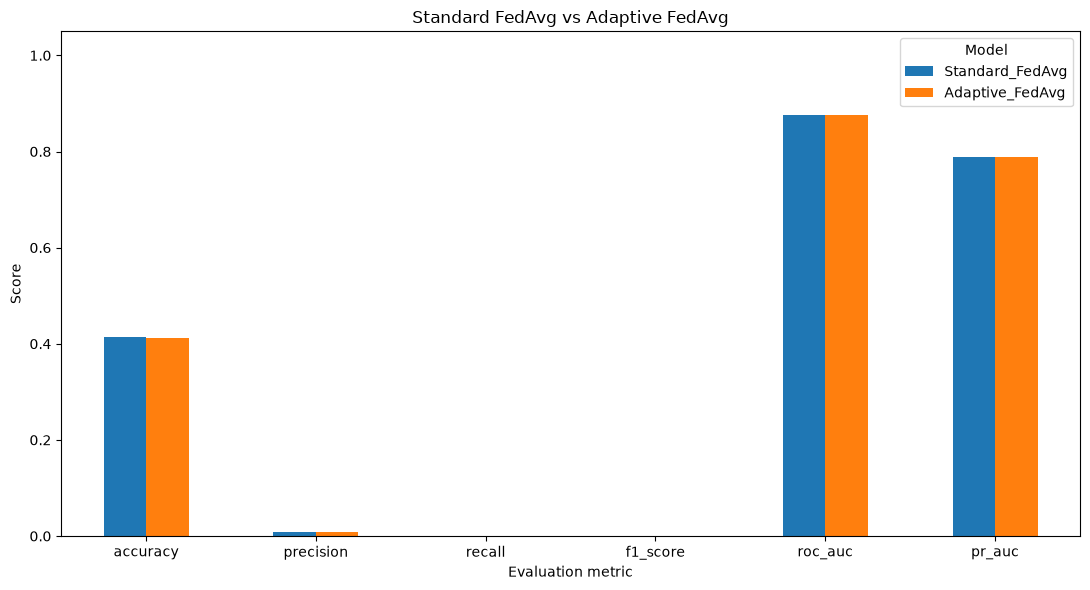

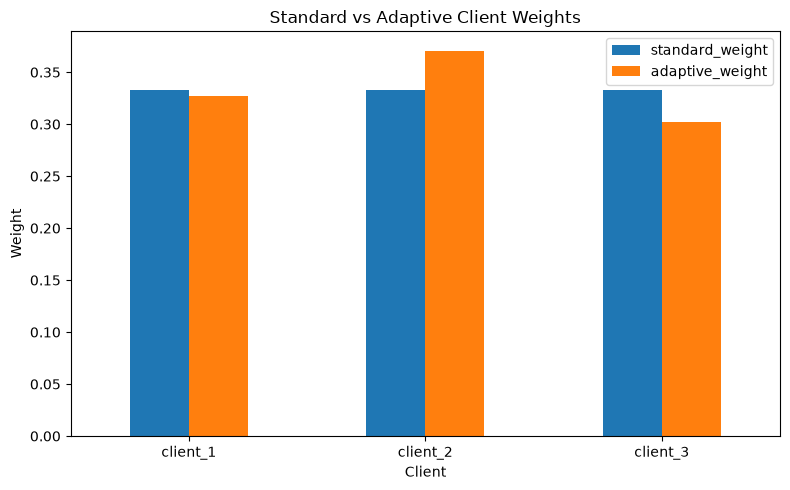

In [7]:
metrics = ["accuracy", "precision", "recall", "f1_score", "roc_auc", "pr_auc"]

plot_df = comparison_df.set_index("model")[metrics].T

ax = plot_df.plot(kind="bar", figsize=(11, 6))
ax.set_title("Standard FedAvg vs Adaptive FedAvg")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation metric")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(OUT / "fedavg_comparison.png", dpi=150)
plt.show()

# Compare the two sets of client weights
weights_df.set_index("client")[
    ["standard_weight", "adaptive_weight"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Standard vs Adaptive Client Weights")
plt.ylabel("Weight")
plt.xlabel("Client")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(OUT / "client_weight_comparison.png", dpi=150)
plt.show()

In [8]:
expected_files = [
    "adaptive_client_weights.csv",
    "standard_fedavg_model.pt",
    "adaptive_fedavg_model.pt",
    "model_comparison_metrics.csv",
    "standard_fedavg_predictions.csv",
    "adaptive_fedavg_predictions.csv",
    "fedavg_comparison.png",
    "client_weight_comparison.png"
]

print("DAY 19 OUTPUT VERIFICATION")
print("-" * 40)

for filename in expected_files:
    path = OUT / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

print("\nFinal metrics:")
display(pd.read_csv(OUT / "model_comparison_metrics.csv"))

print("\nClient weights:")
display(pd.read_csv(OUT / "adaptive_client_weights.csv"))

DAY 19 OUTPUT VERIFICATION
----------------------------------------
adaptive_client_weights.csv: OK
standard_fedavg_model.pt: OK
adaptive_fedavg_model.pt: OK
model_comparison_metrics.csv: OK
standard_fedavg_predictions.csv: OK
adaptive_fedavg_predictions.csv: OK
fedavg_comparison.png: OK
client_weight_comparison.png: OK

Final metrics:


,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Standard_FedAvg,0.413275,0.007968,0.000462,0.000873,0.876633,0.789229
1,Adaptive_FedAvg,0.412786,0.007849,0.000462,0.000872,0.876200,0.788830



Client weights:


,client,training_edges,standard_weight,update_norm,reliability_factor,adaptive_weight
0,client_1,66756,0.333337,0.400369,0.500000,0.326987
1,client_2,66755,0.333332,0.305792,0.566965,0.370775
2,client_3,66755,0.333332,0.465926,0.462163,0.302238


# will have the two global models, client-weight table, evaluation metrics, predictions, and comparison plots.

Project note: This adaptive method uses update magnitude as a heuristic. Because raw update norms can reveal information about clients, this weighting procedure is not itself privacy-preserving. It is also separate from the noise-based privacy prototype implemented on Day 17
 
 # - two global models: One model uses normal FedAvg, and the other uses adaptive FedAvg.
- Client-weight table: Shows how much importance each client gets.
- Evaluation metrics: Show how well each model detects attacks.
- Predictions: Show what attacks the models predicted.
- Comparison plots: Graphs comparing both models.
Privacy note: Adaptive weighting uses how much each client's model changes to decide its importance. This information may reveal something about the client, so adaptive weighting alone does not guarantee privacy.